**Task 1: Vague Prompt vs Well-Structured Prompt**

###Aim

To see how the quality of a prompt changes the quality of the answer from a language model.

###Theory

A prompt is an instruction or question given to a language model. An unclear prompt may produce a general answer, while a clear prompt can produce a more useful response.

A well-structured prompt has four parts:

Role: Who the model should act as.

Task: What the model should do.

Format: How the answer should look.

Constraints: Limits such as word count or tone.

A clear prompt reduces confusion and makes the answer easier to control. Temperature controls the randomness of the response, while maximum tokens limit its length.

###Diagram

Role + Task + Format + Constraints
↓
Structured Prompt → LLM → Focused Answer

Vague Prompt → LLM → General Answer

###Conclusion

The vague prompt generated a general answer, while the other prompts generated answers related to specific topics. I learnt that clear instructions help make AI responses more focused and useful.

The task description made the biggest difference because it clearly explained what the AI should do.

In [24]:
!pip -q install groq
from groq import Groq
from getpass import getpass

client = Groq(api_key=getpass("Groq API key: ").strip())
model = "openai/gpt-oss-20b"

def ask(prompt):
    r = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.7,
        max_tokens=200
    )
    return r.choices[0].message.content

def make_prompt(role, task, fmt, constraints):
    return f"Role: {role}\nTask: {task}\nFormat: {fmt}\nConstraints: {constraints}"

prompts = [
    "Explain machine learning.",
    make_prompt("Teacher", "Explain machine learning", "3 bullet points",
                "Use simple words for beginners."),
    make_prompt("HR assistant", "Write a polite leave email",
                "Email with subject", "Under 100 words."),
    make_prompt("Motivational speaker", "Encourage students before exams",
                "Short speech", "Use simple and positive language.")
]

for p in prompts:
    print("\nPROMPT:", p, "\nANSWER:", ask(p))

Groq API key: ··········

PROMPT: Explain machine learning. 
ANSWER: **Machine learning (ML)** is a subfield of artificial intelligence that focuses on building systems that can learn patterns from data, improve their performance over time, and make decisions or predictions without being explicitly programmed for each specific task.

---

## 1. Core Idea
Instead of writing a set of rules for every possible situation, ML models learn a mapping from input data to output labels (or actions) by observing many examples. The learning process adjusts internal parameters so that the model’s predictions get closer to the true values.

---

## 2. Key Components

|

PROMPT: Role: Teacher
Task: Explain machine learning
Format: 3 bullet points
Constraints: Use simple words for beginners. 
ANSWER: - **Learning from data:** Machine learning is like teaching a computer by giving it many examples, so it can spot patterns and make predictions on new, unseen data.  
- **No explicit instructions:** Instea

**Task 2: Zero-Shot Text Classification**

###Aim

To classify text into different categories using a zero-shot classification model without providing examples.

###Theory

Zero-shot classification is a technique in which a model classifies text into given labels without being specifically trained on those labels for the current task.

The model takes a sentence and a list of candidate labels.

It calculates a score for each label.

The label with the highest score is selected as the top label.

Few-shot learning uses a small number of examples, while fine-tuning updates a model using training data.

###Conclusion

The experiment showed that the model can classify different sentences into suitable labels without providing examples. The scores helped compare the relevance of each label. However, the highest score does not always guarantee a correct prediction.

###Reflection Answer

For the sentence that did not fit any label, the model still assigned scores to the available labels. A real application should include an “Other” category or an uncertainty threshold and ask for human review when the prediction is unreliable.

In [21]:
!pip -q install transformers torch pandas
from transformers import pipeline
import pandas as pd

clf = pipeline("zero-shot-classification",
               model="facebook/bart-large-mnli")

data = [
    ("AI helps doctors detect diseases.", ["technology","sports","politics","food"]),
    ("India won a cricket match.", ["technology","sports","politics","food"]),
    ("I am excited about my new phone.", ["happy","sad","angry","worried"]),
    ("I feel disappointed today.", ["happy","sad","angry","worried"]),
    ("My bag has two zippers.", ["technology","sports","politics","food"])
]

rows = []
for sentence, labels in data:
    r = clf(sentence, candidate_labels=labels)
    print("\n", sentence)
    for l, s in zip(r["labels"], r["scores"]):
        print(l, round(s, 3))
    rows.append([sentence, r["labels"][0], round(r["scores"][0], 3)])

print(pd.DataFrame(rows, columns=["Sentence", "Top Label", "Score"]))

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]


 AI helps doctors detect diseases.
technology 0.996
food 0.002
sports 0.001
politics 0.001

 India won a cricket match.
sports 0.993
technology 0.004
food 0.002
politics 0.001

 I am excited about my new phone.
happy 0.994
worried 0.003
angry 0.002
sad 0.001

 I feel disappointed today.
sad 0.712
worried 0.183
angry 0.103
happy 0.002

 My bag has two zippers.
technology 0.82
sports 0.089
politics 0.048
food 0.043
                            Sentence   Top Label  Score
0  AI helps doctors detect diseases.  technology  0.996
1         India won a cricket match.      sports  0.993
2   I am excited about my new phone.       happy  0.994
3         I feel disappointed today.         sad  0.712
4            My bag has two zippers.  technology  0.820


**Task 3: Chain-of-Thought Prompting**

###Aim

To check whether asking a language model to solve a problem step by step improves its answers.

###Theory

Chain-of-thought prompting encourages a language model to break a problem into smaller steps before giving a final answer.

A direct prompt asks for an answer immediately.

A step-by-step prompt asks for an ordered solution.

Step-by-step instructions may help with multi-step calculations.

The model can still make mistakes, so its answers must be checked.

###Diagram

Problem → Direct Prompt → Final Answer

Problem → Step-by-Step Prompt → Steps → Final Answer

###Conclusion

The experiment compared direct and step-by-step answers for three maths problems. The results showed whether asking for steps improved accuracy in this run.

###Reflection Answer

The step-by-step version did not necessarily give better answers every time. Its performance should be compared with the correct answers because a detailed solution can also contain calculation errors.

In [22]:
problems = [
    ("A ₹1500 item has 20% discount and then 5% tax. Final price?", "1260"),
    ("3 workers make 48 items in 4 hours. How many do 5 workers make in 6 hours?", "120"),
    ("A bus travels 180 km at 60 km/h and 120 km at 40 km/h. Average speed?", "50")
]

rows = []
for q, correct in problems:
    direct = ask(q)
    steps = ask(q + " Explain your solution step by step.")
    print("\nProblem:", q, "\nDirect:", direct, "\nStep-by-step:", steps)
    rows.append([q, correct, direct, steps])

print(pd.DataFrame(rows, columns=[
    "Problem", "Correct Answer", "Direct Answer", "Step-by-Step Answer"
]))


Problem: A ₹1500 item has 20% discount and then 5% tax. Final price? 
Direct: First apply the 20 % discount:

- Discount = 20 % of ₹1,500 = 0.20 × 1,500 = **₹300**  
- Price after discount = ₹1,500 – ₹300 = **₹1,200**

Now add the 5 % tax on the discounted price:

- Tax = 5 % of ₹1,200 
Step-by-step: **Step‑by‑step calculation**

| Step | What we do | Formula | Result |
|------|------------|---------|--------|
| 1 | **Original price** of the item | – | ₹1500 |
| 2 | **Apply 20 % discount** | Discount = 20 % of ₹1500 = \(0.20 \times 1500\) | ₹300 |
| 3 | **Price after discount** | New

Problem: 3 workers make 48 items in 4 hours. How many do 5 workers make in 6 hours? 
Direct: First find the production rate per worker per hour.

- 3 workers produce 48 items in 4 hours  
  \[
  \text{Rate per worker-hour} = \frac{48\text{ items}}{3\text{ workers}\times 4\text{ hours}}
  = \frac{48}{12}=4\text{ items per worker-hour}.
  \]

Now use this rate for 5 workers working 6 hours:

\[
\ 
Step-by-

# Task 4: Image Captioning and Zero-Shot Image Classification

### Aim
To generate captions for images and classify them using zero-shot image classification models.

### Theory
Multimodal AI works with different types of data, such as images and text.

- Image captioning describes an image in words.
- A vision-language model connects visual information with language.
- CLIP compares an image with text labels and assigns a score to each label.
- The label with the highest score is selected as the top prediction.
- The prediction may be incorrect if the image is unclear or the labels are unsuitable.

### Diagram
Input Image → Captioning Model → Image Caption

Input Image + Text Labels → CLIP Model → Label Scores

### Conclusion
The models generated captions and classified the uploaded images using the given labels. The results showed how AI can connect visual information with text, although some predictions may be incorrect.

### Reflection Answer
The model may make mistakes when an image is unclear or when similar labels are provided. Using clearer images and more suitable labels may improve the results.

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Saving Image 3.jpg to Image 3 (4).jpg
Saving Image2.jpg to Image2 (4).jpg
Saving Image1.jpg to Image1 (4).jpg


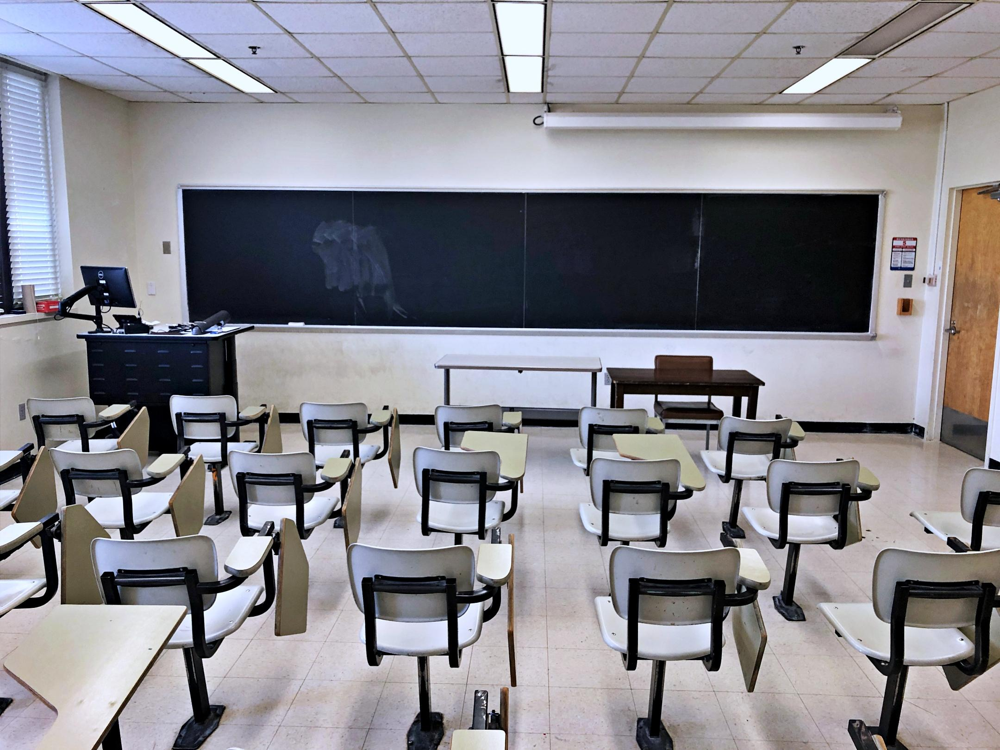

Image 3 (4).jpg 
Caption: a classroom with a blackboard and white chairs 
Scores: [{'score': 0.9999557733535767, 'label': 'a photo of a classroom'}, {'score': 4.11727924074512e-05, 'label': 'a photo of a building'}, {'score': 2.649951056810096e-06, 'label': 'a photo of nature'}, {'score': 3.9016427422211564e-07, 'label': 'a photo of food'}]


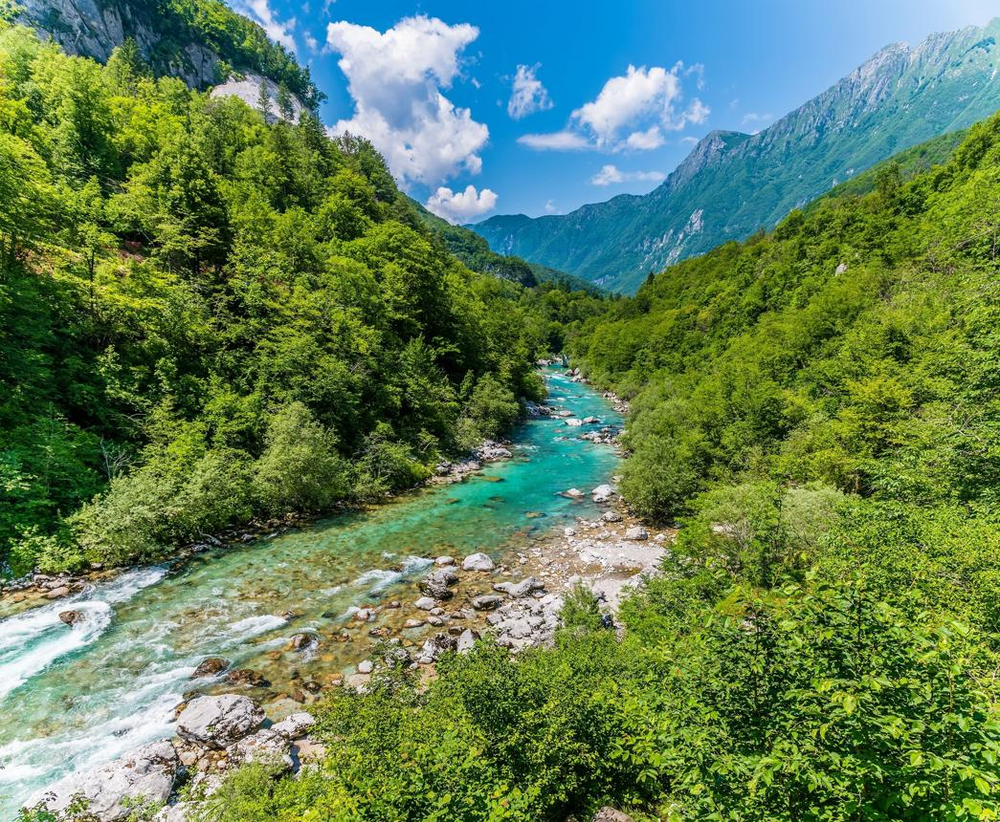

Image2 (4).jpg 
Caption: the socta river in the mountains of socta valley, socta valley, socta valley, soc 
Scores: [{'score': 0.9908425807952881, 'label': 'a photo of nature'}, {'score': 0.006501445081084967, 'label': 'a photo of a classroom'}, {'score': 0.0016040324699133635, 'label': 'a photo of a building'}, {'score': 0.0010519562056288123, 'label': 'a photo of food'}]


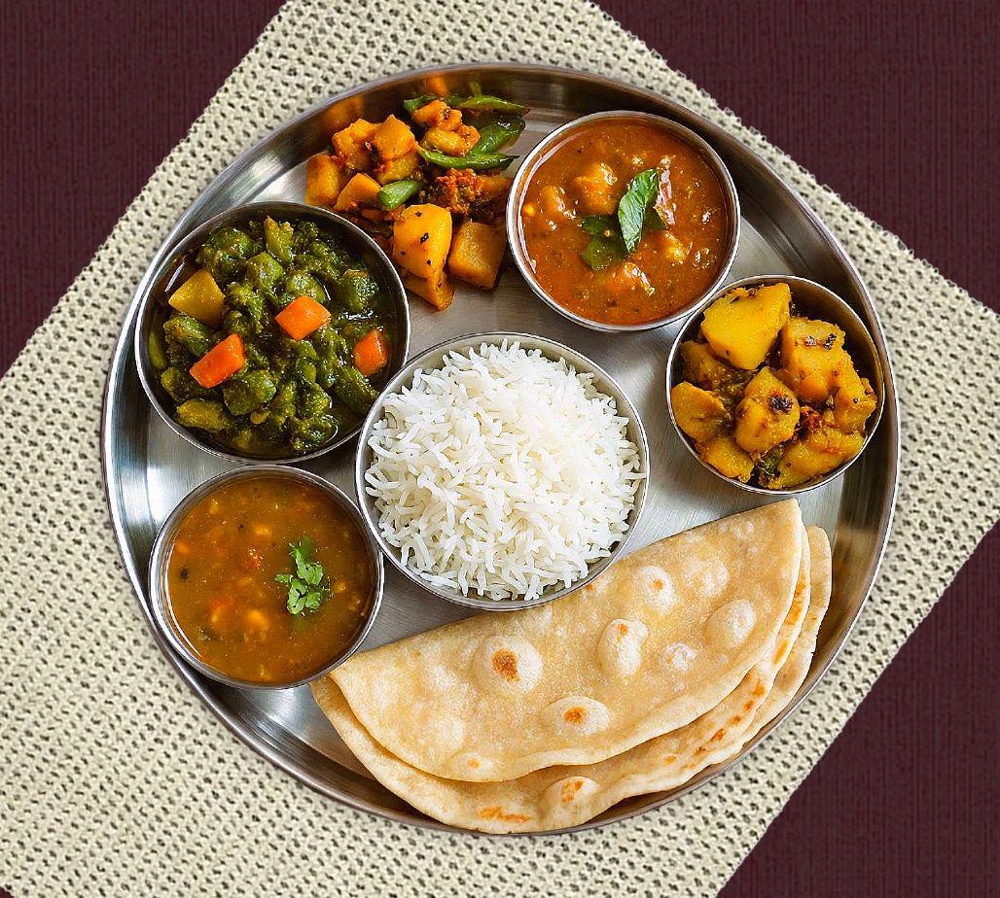

Image1 (4).jpg 
Caption: a plate of food with rice, vegetables and sauces 
Scores: [{'score': 0.9993770718574524, 'label': 'a photo of food'}, {'score': 0.00030876355594955385, 'label': 'a photo of a classroom'}, {'score': 0.0002518613182473928, 'label': 'a photo of nature'}, {'score': 6.234408647287637e-05, 'label': 'a photo of a building'}]
             Image                                            Caption  \
0  Image 3 (4).jpg     a classroom with a blackboard and white chairs   
1   Image2 (4).jpg  the socta river in the mountains of socta vall...   
2   Image1 (4).jpg   a plate of food with rice, vegetables and sauces   

                Top Label  Score  
0  a photo of a classroom  1.000  
1       a photo of nature  0.991  
2         a photo of food  0.999  


In [23]:
!pip -q install transformers torch pillow pandas
from transformers import BlipProcessor, BlipForConditionalGeneration, pipeline
from google.colab import files
from PIL import Image
import pandas as pd

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model_img = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32")

labels = ["a photo of food", "a photo of nature",
          "a photo of a classroom", "a photo of a building"]
rows = []

for name in files.upload():
    img = Image.open(name).convert("RGB")
    display(img)
    inputs = processor(images=img, return_tensors="pt")
    caption = processor.decode(
        model_img.generate(**inputs, max_new_tokens=30)[0],
        skip_special_tokens=True
    )
    scores = clip(img, candidate_labels=labels)
    print(name, "\nCaption:", caption, "\nScores:", scores)
    rows.append([name, caption, scores[0]["label"], round(scores[0]["score"], 3)])

print(pd.DataFrame(rows, columns=["Image", "Caption", "Top Label", "Score"]))

# Task 5: AI-Assisted Data Cleaning

### Aim
To use a language model to generate pandas code for cleaning a messy dataset.

### Theory
AI-assisted data cleaning uses a language model to suggest code for correcting data problems.

- Pandas helps organize and clean data.
- Missing values can be handled using suitable methods.
- Inconsistent text can be standardized.
- Invalid values must be identified and corrected.
- AI-generated code should be checked before execution to avoid errors.

### Conclusion
The experiment showed how AI can suggest data-cleaning code. The dataset was cleaned by standardizing names, converting marks to numeric values, and replacing invalid marks with missing values.

### Reflection Answer
No, I would not trust AI-generated code on a real company dataset without checking it. The code may remove valid data or make incorrect changes, so it must be tested first.

In [18]:
!pip -q install groq pandas
import pandas as pd
from groq import Groq
from getpass import getpass

client = Groq(api_key=getpass("Groq API key:"))

df = pd.DataFrame({
    "Name": ["ANIKET", "arya", "Dip", "NEHA", None, "sam", "Pooja", "JAY"],
    "Marks": [85, 92, None, 110, 76, "absent", 88, 65]
})

print("Before Cleaning:\n", df)

prompt = """Write pandas code only to clean df:
standardize names, convert marks to numeric,
replace invalid marks outside 0-100 with NaN,
and keep missing values as NaN."""

code = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[{"role": "user", "content": prompt}]
).choices[0].message.content

print("\nAI Generated Code:\n", code)

# Reviewed, safe cleaning code
clean = df.copy()
clean["Name"] = clean["Name"].str.strip().str.title()
clean["Marks"] = pd.to_numeric(clean["Marks"], errors="coerce")
clean.loc[~clean["Marks"].between(0, 100), "Marks"] = float("nan")

print("\nAfter Cleaning:\n", clean)

Groq API key:··········
Before Cleaning:
      Name   Marks
0  ANIKET      85
1    arya      92
2     Dip    None
3    NEHA     110
4    None      76
5     sam  absent
6   Pooja      88
7     JAY      65

AI Generated Code:
 ```python
import pandas as pd

# 1. Standardise the name column
df['Name'] = df['Name'].str.strip().str.title()

# 2. Convert marks to numeric (coerce errors to NaN)
df['Mark'] = pd.to_numeric(df['Mark'], errors='coerce')

# 3. Replace out‑of‑range marks (outside 0–100) with NaN
df.loc[(df['Mark'] < 0) | (df['Mark'] > 100), 'Mark'] = pd.NA
```


After Cleaning:
      Name  Marks
0  Aniket   85.0
1    Arya   92.0
2     Dip    NaN
3    Neha    NaN
4    None   76.0
5     Sam    NaN
6   Pooja   88.0
7     Jay   65.0


# Task 6: Jinja2 Templating for a Flask Page

### Aim
To create an HTML page using Jinja2 templates to display AI responses and chat history.

### Theory
Jinja2 is a templating engine used to generate dynamic HTML pages. Flask is a Python web framework used to build web applications.

- Variables display values such as a user's name and AI response.
- Loops display multiple questions and answers.
- Conditions show a message when an answer is empty.
- The AI function receives a prompt and returns a response.
- API keys should be kept secure on the server.

### Diagram
User Prompt → AI Function → Response → Jinja2 Template → HTML Page

### Conclusion
The experiment demonstrated how Jinja2 displays user details, AI responses and chat history in an HTML page. The page was rendered and saved as an HTML file.

### Reflection Answer
The program is missing a complete Flask server and a real AI connection. It uses a simple Python function instead of a live AI service.

In [19]:
!pip -q install jinja2
from jinja2 import Template
from IPython.display import HTML, display

def get_ai_response(prompt):
    return "AI answer: " + prompt

questions = ["What is AI?", "What is ML?", "What is NLP?", "What is GenAI?"]
chat = [{"q": q, "a": get_ai_response(q)} for q in questions]

template = Template("""
<html><body>
<h2>Hello, {{ name }}!</h2>
<h3>AI Response</h3><p>{{ answer }}</p>
<h3>Chat History</h3>
{% for item in chat %}
<p><b>Q:</b> {{ item.q }}<br><b>A:</b>
{{ item.a if item.a else "No answer yet" }}</p>
{% endfor %}
</body></html>
""")

page = template.render(name="Aniket", answer=get_ai_response("Explain GenAI"), chat=chat)

print(page)
display(HTML(page))
with open("ai_page.html", "w") as f:
    f.write(page)

print("HTML page saved!")


<html><body>
<h2>Hello, Aniket!</h2>
<h3>AI Response</h3><p>AI answer: Explain GenAI</p>
<h3>Chat History</h3>

<p><b>Q:</b> What is AI?<br><b>A:</b>
AI answer: What is AI?</p>

<p><b>Q:</b> What is ML?<br><b>A:</b>
AI answer: What is ML?</p>

<p><b>Q:</b> What is NLP?<br><b>A:</b>
AI answer: What is NLP?</p>

<p><b>Q:</b> What is GenAI?<br><b>A:</b>
AI answer: What is GenAI?</p>

</body></html>


HTML page saved!
